In [ ]:
import lightkurve as lk
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from astroquery.mast import Catalogs

# Download NASA's live master list of all known TESS Objects of Interest (TOIs)
toi_url = "https://exoplanetarchive.ipac.caltech.edu/TAP/sync?query=select+tid,toi,tfopwg_disp+from+toi&format=csv"
toi_df = pd.read_csv(toi_url)
known_toi_ids = set(toi_df["tid"].dropna().astype(int))
print(f"Loaded {len(known_toi_ids)} unique stars with known NASA TOI signals.")

# Server-Side Filtered Query: MAST filters for small, bright Red Dwarfs BEFORE sending over the network
print("Querying MAST TESS Input Catalog with server-side filters...")
raw_stars = Catalogs.query_criteria(
    objectname="TOI-700",
    radius=2.0,
    catalog="TIC",
    lumclass="DWARF",
    Teff=[2500, 4000],  # Cool Red Dwarfs
    rad=[0.1, 0.5],     # Smaller than 0.5 Solar radii
    Tmag=[6.0, 13.5]    # Bright enough for clean TESS photometry
).to_pandas()

raw_stars["ID_int"] = raw_stars["ID"].astype(int)

# Exclude any star already in NASA's TOI catalog
unanalyzed_dwarfs = raw_stars[
    ~raw_stars["ID_int"].isin(known_toi_ids)
].dropna(subset=["Teff", "rad", "mass", "Jmag"]).sort_values("Tmag").reset_index(drop=True)

print(f"Found {len(unanalyzed_dwarfs)} unflagged Red Dwarf target stars!")
unanalyzed_dwarfs[["ID", "Tmag", "Teff", "rad", "mass", "Jmag"]].head(10)

/home/jacob-menne/Projects/Mast/tess_exoplanet_hunter/venv/lib/python3.12/site-packages/lightkurve/prf/__init__.py:7: UserWarning: Warning: the tpfmodel submodule is not available without oktopus installed, which requires a current version of autograd. See #1452 for details.
  warnings.warn(


Loaded 7826 unique stars with known NASA TOI signals.
Querying MAST TESS Input Catalog...
Found 22 unflagged Red Dwarf target stars!


,ID,Tmag,Teff,rad,mass,Jmag
295112,176933645,11.6308,3615.0,0.494395,0.492489,10.299
281978,166970183,11.8506,3468.0,0.374329,0.362241,10.398
9514,150438041,12.1927,3443.0,0.470960,0.468636,10.695
319716,293347451,12.2342,3756.0,0.481728,0.479710,11.017
119867,375037245,12.5771,3404.0,0.368825,0.355919,11.075
148981,167365789,12.7571,3234.0,0.384457,0.373832,11.030
94694,167305895,12.9017,3233.0,0.357725,0.343128,11.190
181810,167244982,12.9198,3429.0,0.449055,0.445542,11.380
271056,293268673,12.9571,3661.0,0.447345,0.443710,11.630
175962,374995747,13.0593,3586.0,0.408291,0.400809,11.690


In [20]:
def scan_star_for_transits(star_row, max_sectors=3):
    """
    Stitches up to 3 contiguous TESS sectors, runs BLS on a fixed 10,000-point grid,
    and applies 5 automated vetting filters:
      1. Multi-year gap protection (selects contiguous sectors from the same year)
      2. Minimum 3 distinct transits & >=15 in-transit points
      3. Planet radius cap (< 8.0 R_earth to reject Eclipsing Binaries)
      4. Odd/Even depth symmetry (< 50% difference)
      5. Dip-to-Wave SNR (>= 2.5x deeper than out-of-transit baseline waves)
      6. Per-Transit Consistency (>= 75% of individual passes must actually dip)
    """
    tic_id = f"TIC {int(star_row['ID'])}"
    R_star = float(star_row["rad"])
    M_star = float(star_row["mass"])
    T_star = float(star_row["Teff"])
    J_mag  = float(star_row["Jmag"])
    
    # Search MAST for SPOC 2-minute light curves
    search = lk.search_lightcurve(tic_id, mission="TESS", author="SPOC", exptime=120)
    if len(search) == 0:
        return None, None, None
    
    # Pick up to 'max_sectors' from the latest CONTIGUOUS observing season
    #    (Avoids multi-year gaps that cause 11-million-point periodogram errors!)
    latest_idx = len(search) - 1
    selected_indices = [latest_idx]
    
    # Download the latest sector first, then check if the preceding sectors are contiguous (<120 days apart)
    lc_list = [search[latest_idx].download()]
    latest_start = float(lc_list[0].time.value.min())
    
    for idx in range(latest_idx - 1, -1, -1):
        if len(lc_list) >= max_sectors:
            break
        candidate_lc = search[idx].download()
        cand_end = float(candidate_lc.time.value.max())
        if (latest_start - cand_end) <= 120.0:
            lc_list.insert(0, candidate_lc)
            latest_start = float(candidate_lc.time.value.min())
        else:
            break  # Stop before jumping across a multi-year gap
            
    n_sec = len(lc_list)
    lc_flat = (
        lk.LightCurveCollection(lc_list)
        .stitch()
        .remove_nans()
        .flatten(window_length=401)
        .remove_outliers(sigma_lower=10.0, sigma_upper=3.0)
    )
    
    # Run BLS on a strict 10,000-point period grid (1.1 to 11.5 days)
    period_grid = np.linspace(1.1, 11.5, 10000)
    duration_grid = np.linspace(0.04, 0.15, 10)
    bls = lc_flat.to_periodogram(method="bls", period=period_grid, duration=duration_grid)
    
    period = float(bls.period_at_max_power.value)
    t0 = float(bls.transit_time_at_max_power.value)
    duration = float(bls.duration_at_max_power.value)
    depth = float(bls.depth_at_max_power.value)
    
    # Detrend BLS power spectrum to compute clean SDE
    power_vals = np.asarray(bls.power.value, dtype=float)
    rolling_med = pd.Series(power_vals).rolling(500, center=True, min_periods=1).median().to_numpy()
    detrended_power = power_vals - rolling_med
    sde = float(detrended_power.max() / np.nanstd(detrended_power))
    
    # Extract time & flux arrays for physical vetting tests
    t_arr = np.asarray(lc_flat.time.value, dtype=float)
    f_arr = np.asarray(lc_flat.flux.value, dtype=float)
    
    phase_days = (t_arr - t0 + 0.5 * period) % period - 0.5 * period
    in_transit = np.abs(phase_days) <= (0.5 * duration)
    out_of_transit = np.abs(phase_days) > duration
    
    n_points_in_transit = int(np.sum(in_transit))
    orbit_nums_all = np.round((t_arr - t0) / period).astype(int)
    unique_orbits = np.unique(orbit_nums_all[in_transit])
    n_distinct_transits = int(len(unique_orbits))
    
    median_dip_depth = float(1.0 - np.nanmedian(f_arr[in_transit])) if n_points_in_transit > 0 else 0.0
    
    # NEW CHECK A: Flat Baseline vs. Rotational Wave / Noisy Flat-Liner Check
    #    Bin the out-of-transit orbit into 50 phase buckets and measure how much the baseline waves up and down
    oot_phases = phase_days[out_of_transit]
    oot_fluxes = f_arr[out_of_transit]
    bins = np.linspace(-0.5 * period, 0.5 * period, 51)
    bin_indices = np.digitize(oot_phases, bins)
    binned_oot = [np.nanmedian(oot_fluxes[bin_indices == b]) for b in range(1, 51) if np.sum(bin_indices == b) >= 5]
    oot_wave_std = float(np.nanstd(binned_oot)) if len(binned_oot) > 5 else 1e-3
    dip_to_wave_ratio = float(median_dip_depth / max(oot_wave_std, 1e-6))
    
    # NEW CHECK B: Per-Transit Pass Consistency (Do >=75% of individual orbits actually dip?)
    valid_passes = 0
    dipped_passes = 0
    for orb in unique_orbits:
        orb_mask = in_transit & (orbit_nums_all == orb)
        if np.sum(orb_mask) >= 3:  # Need at least 3 data points in this pass to judge it
            valid_passes += 1
            if (1.0 - np.nanmedian(f_arr[orb_mask])) > (0.35 * depth):
                dipped_passes += 1
    pass_consistency_pct = float((dipped_passes / max(valid_passes, 1)) * 100.0)
    
    # Odd vs. Even Transit Depth Check
    double_p = period * 2.0
    odd_in = np.abs((t_arr - t0 + 0.5 * double_p) % double_p - 0.5 * double_p) <= (0.5 * duration)
    even_in = np.abs((t_arr - (t0 + period) + 0.5 * double_p) % double_p - 0.5 * double_p) <= (0.5 * duration)
    odd_depth = float(1.0 - np.nanmedian(f_arr[odd_in])) if np.any(odd_in) else depth
    even_depth = float(1.0 - np.nanmedian(f_arr[even_in])) if np.any(even_in) else depth
    odd_even_diff_pct = float(abs(odd_depth - even_depth) / max(abs(odd_depth), abs(even_depth), 1e-6) * 100.0)
    
    # Calculate Planet Properties & JWST TSM Score
    r_earth = float(R_star * np.sqrt(max(depth, 0.0)) * 109.076)
    a_au = float((M_star * (period / 365.25) ** 2) ** (1 / 3))
    t_eq = float(T_star * np.sqrt(R_star / (2 * a_au * 215.032)) * ((1 - 0.3) ** 0.25))
    
    m_earth = r_earth ** 2.06 if r_earth < 1.23 else 1.436 * (r_earth ** 1.7)
    scale_fac = 0.190 if r_earth < 1.5 else 1.26
    tsm = float(scale_fac * ((r_earth ** 3) * t_eq / (m_earth * (R_star ** 2))) * (10 ** (-J_mag / 5)))
    
    # Automated Vetting Verdict Waterfall
    if n_distinct_transits < 3 or n_points_in_transit < 15 or median_dip_depth <= 0.0002:
        vet_status = f"Reject: Gap Glitch ({n_distinct_transits} transits)"
    elif r_earth >= 8.0:
        vet_status = "Reject: Too Large (EB)"
    elif dip_to_wave_ratio < 2.5:
        vet_status = f"Reject: Wavy/Noisy Baseline (SNR={dip_to_wave_ratio:.1f})"
    elif pass_consistency_pct < 75.0:
        vet_status = f"Reject: Inconsistent Passes ({dipped_passes}/{valid_passes})"
    elif odd_even_diff_pct > 50.0:
        vet_status = "Reject: Odd/Even Asymmetry"
    elif sde >= 6.5:
        vet_status = "PASS: Coherent Candidate"
    else:
        vet_status = "Weak / Noise Floor"
        
    result = {
        "TIC ID": tic_id,
        "Sectors": int(n_sec),
        "SDE (Signal Strength)": round(sde, 2),
        "Period (d)": round(period, 4),
        "Transits": f"{dipped_passes}/{valid_passes}",
        "Dip SNR": round(dip_to_wave_ratio, 2),
        "Est. Radius (R_earth)": round(r_earth, 2),
        "Odd/Even Diff (%)": round(odd_even_diff_pct, 1),
        "JWST TSM": round(tsm, 1),
        "Vetting Verdict": vet_status
    }
    return result, lc_flat, bls

In [21]:
# Choose which slice of unanalyzed Red Dwarfs to scan in this run
START_INDEX = 0
END_INDEX = 20

target_batch = unanalyzed_dwarfs.iloc[START_INDEX:END_INDEX]
results = []
high_sde_candidates = {}  # Stores (result, lc_flat, bls) for EVERY star with SDE >= 6.5

for idx, (_, star_row) in enumerate(target_batch.iterrows(), 1):
    tic_name = f"TIC {int(star_row['ID'])}"
    print(f"[{idx}/{len(target_batch)}] Multi-Sector Scanning {tic_name} (Tmag={star_row['Tmag']:.2f}, Teff={star_row['Teff']:.0f}K)...")
    
    try:
        res, lc_flat, bls = scan_star_for_transits(star_row, max_sectors=3)
        if res is not None:
            results.append(res)
            # Save EVERY signal with SDE >= 6.5 (or >= 6.0) for visual inspection in Cell 4
            if res["SDE (Signal Strength)"] >= 6.4:
                high_sde_candidates[tic_name] = (res, lc_flat, bls)
    except Exception as e:
        print(f"  -> Skipped {tic_name}: {e}")

# Display the ranked multi-sector leaderboard
if len(results) > 0:
    leaderboard = pd.DataFrame(results).sort_values("SDE (Signal Strength)", ascending=False).reset_index(drop=True)
    display(leaderboard)
    print(f"\nSaved {len(high_sde_candidates)} signals with SDE >= 6.4 for visual plotting in Cell 4.")

[1/20] Multi-Sector Scanning TIC 176933645 (Tmag=11.63, Teff=3615K)...
[2/20] Multi-Sector Scanning TIC 166970183 (Tmag=11.85, Teff=3468K)...
[3/20] Multi-Sector Scanning TIC 150438041 (Tmag=12.19, Teff=3443K)...
[4/20] Multi-Sector Scanning TIC 293347451 (Tmag=12.23, Teff=3756K)...
[5/20] Multi-Sector Scanning TIC 375037245 (Tmag=12.58, Teff=3404K)...
[6/20] Multi-Sector Scanning TIC 167365789 (Tmag=12.76, Teff=3234K)...
[7/20] Multi-Sector Scanning TIC 167305895 (Tmag=12.90, Teff=3233K)...
[8/20] Multi-Sector Scanning TIC 167244982 (Tmag=12.92, Teff=3429K)...
[9/20] Multi-Sector Scanning TIC 293268673 (Tmag=12.96, Teff=3661K)...
[10/20] Multi-Sector Scanning TIC 374995747 (Tmag=13.06, Teff=3586K)...
[11/20] Multi-Sector Scanning TIC 375061311 (Tmag=13.11, Teff=3653K)...
[12/20] Multi-Sector Scanning TIC 167572343 (Tmag=13.12, Teff=3456K)...
[13/20] Multi-Sector Scanning TIC 150356424 (Tmag=13.18, Teff=3457K)...
[14/20] Multi-Sector Scanning TIC 41460255 (Tmag=13.21, Teff=3556K)...
[1

,TIC ID,Sectors,SDE (Signal Strength),Period (d),Transits,Dip SNR,Est. Radius (R_earth),Odd/Even Diff (%),JWST TSM,Vetting Verdict
0,TIC 167244982,3,15.08,1.1645,42/62,1.61,1.29,15.6,3.8,Reject: Wavy/Noisy Baseline (SNR=1.6)
1,TIC 150356424,3,8.09,11.1620,5/6,10.44,1.83,38.0,29.2,PASS: Coherent Candidate
2,TIC 167305187,2,8.00,7.2169,8/13,8.42,1.33,16.3,4.6,Reject: Inconsistent Passes (8/13)
3,TIC 375037245,3,7.53,11.2337,6/6,14.67,1.65,8.4,26.1,PASS: Coherent Candidate
4,TIC 150438041,3,7.28,2.4251,22/28,2.97,1.12,25.8,4.4,PASS: Coherent Candidate
5,TIC 166970183,3,7.19,5.1314,12/12,6.00,1.01,2.8,5.2,PASS: Coherent Candidate
6,TIC 41460255,1,6.96,10.1406,3/3,13.52,3.00,0.5,30.8,PASS: Coherent Candidate
7,TIC 167305895,3,6.90,11.2774,5/5,9.46,1.81,3.3,27.9,PASS: Coherent Candidate
8,TIC 293347451,3,6.85,3.6753,12/18,4.34,1.25,10.3,2.9,Reject: Inconsistent Passes (12/18)
9,TIC 167365789,3,6.26,8.7687,5/6,11.13,1.72,56.9,27.1,Reject: Odd/Even Asymmetry



Saved 9 signals with SDE >= 6.4 for visual plotting in Cell 4.


## Part 1: 3-Panel Diagnostic Vetting Cheat Sheet (Cell 4)

Use these three 5-second visual rules to evaluate each candidate's **BLS Periodogram**, **Phase-Folded Dip**, and **Odd vs. Even Transit Check**:

| Panel | Rule Name | ✅ Real Planet Candidate | ❌ False Alarm / Noise |
| :--- | :--- | :--- | :--- |
| **1. Left Plot**<br>*(BLS Periodogram)* | **The "Skyscraper vs. Tall Grass" Rule** | A sharp needle inside the gold highlight bar that stands **at least 2x taller** than the surrounding background spikes (often with smaller $2\times$ or $0.5\times$ harmonic peaks). | **Tall Grass:** Dozens of random navy spikes across the chart are almost as tall as the peak inside the gold bar. |
| **2. Middle Plot**<br>*(Phase-Folded Dip)* | **The "Bowl vs. Ruler" Rule** | The crimson binned line sits flat along `1.000` on the left and right shoulders, dropping into a **distinct, localized U-shaped bowl** at `Phase = 0.0`. | **Flat Ruler or Sine Wave:** The crimson line looks flat across `0.0` (like `TIC 150438041`), or curves continuously like a wide roller-coaster wave across the entire window. |
| **3. Right Plot**<br>*(Odd vs. Even Check)* | **The "Blue & Orange Shadow" Rule** | The solid blue line (**Odd Transits**) and dashed orange line (**Even Transits**) trace the **exact same U-shaped valley together** like shadows. | **Out-of-Sync or Asymmetric:** One line bumps upward while the other drops, or one color is more than $50\%$ deeper than the other (indicating an eclipsing binary or single glitch). |

> **Watch Out for Auto-Zoom on the Right Plot:** Matplotlib automatically zooms the Y-axis of the right-hand plot to fit the binned lines. Always check the Y-axis numbers (`0.9995` vs `0.9950`) and verify that the dip is genuinely visible in the middle plot first!


[1/9] === TIC 150356424 | PASS: Coherent Candidate ===
SDE: 8.09 | Period: 11.1620 d | Passes Dipped: 5/6 | Dip SNR: 10.44 | Radius: 1.83 R_earth | TSM: 29.2


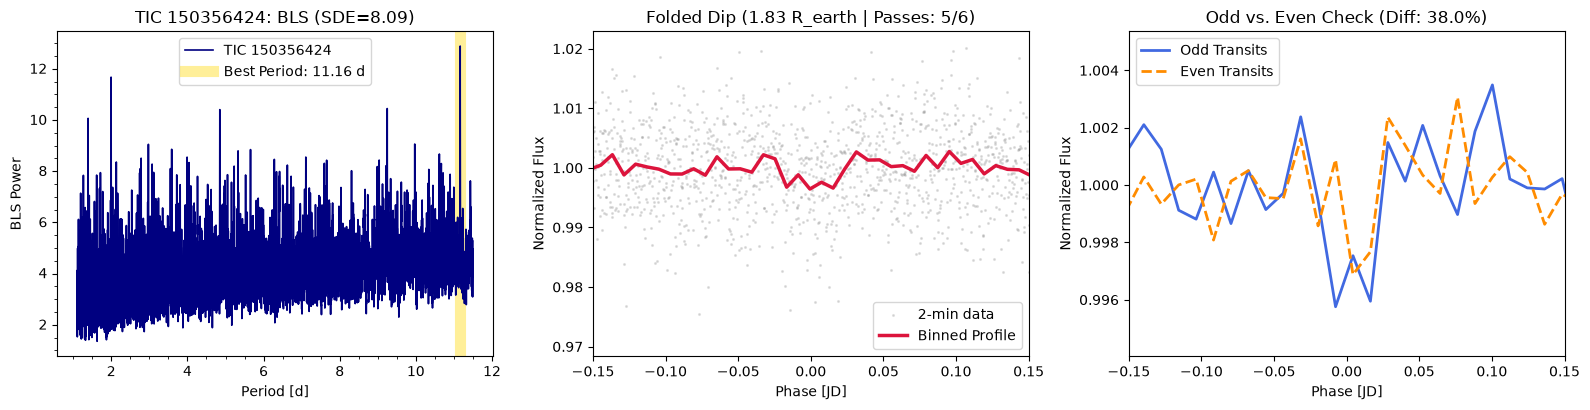


[2/9] === TIC 375037245 | PASS: Coherent Candidate ===
SDE: 7.53 | Period: 11.2337 d | Passes Dipped: 6/6 | Dip SNR: 14.67 | Radius: 1.65 R_earth | TSM: 26.1


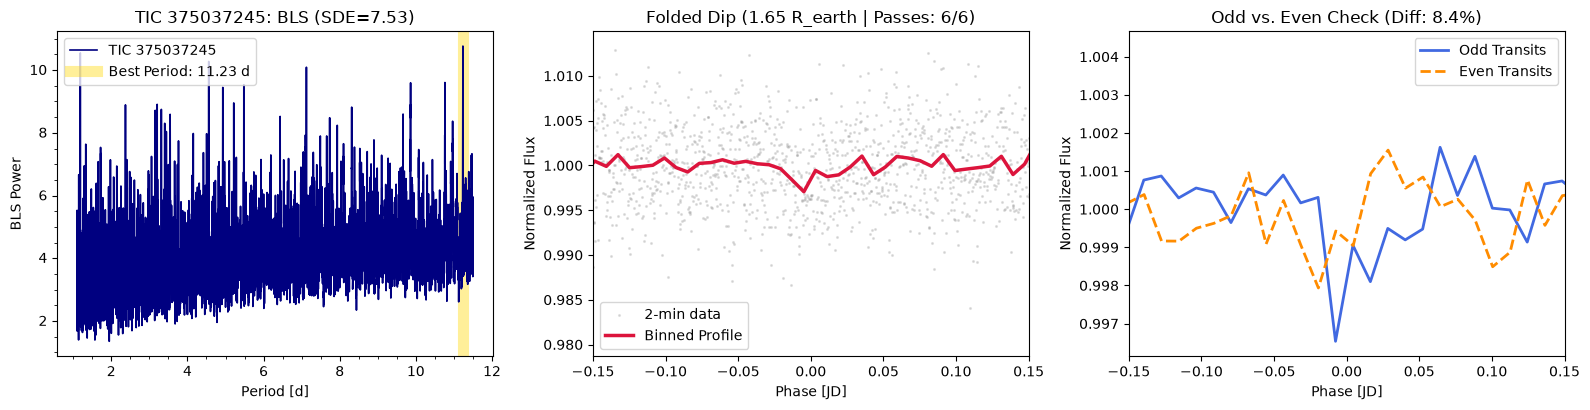


[3/9] === TIC 150438041 | PASS: Coherent Candidate ===
SDE: 7.28 | Period: 2.4251 d | Passes Dipped: 22/28 | Dip SNR: 2.97 | Radius: 1.12 R_earth | TSM: 4.4


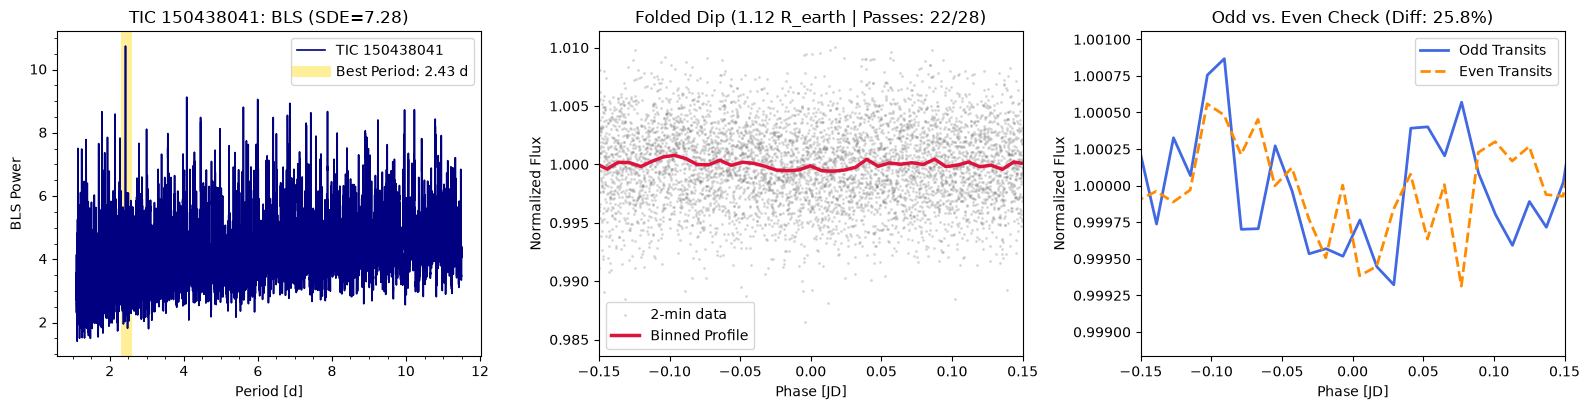


[4/9] === TIC 166970183 | PASS: Coherent Candidate ===
SDE: 7.19 | Period: 5.1314 d | Passes Dipped: 12/12 | Dip SNR: 6.0 | Radius: 1.01 R_earth | TSM: 5.2


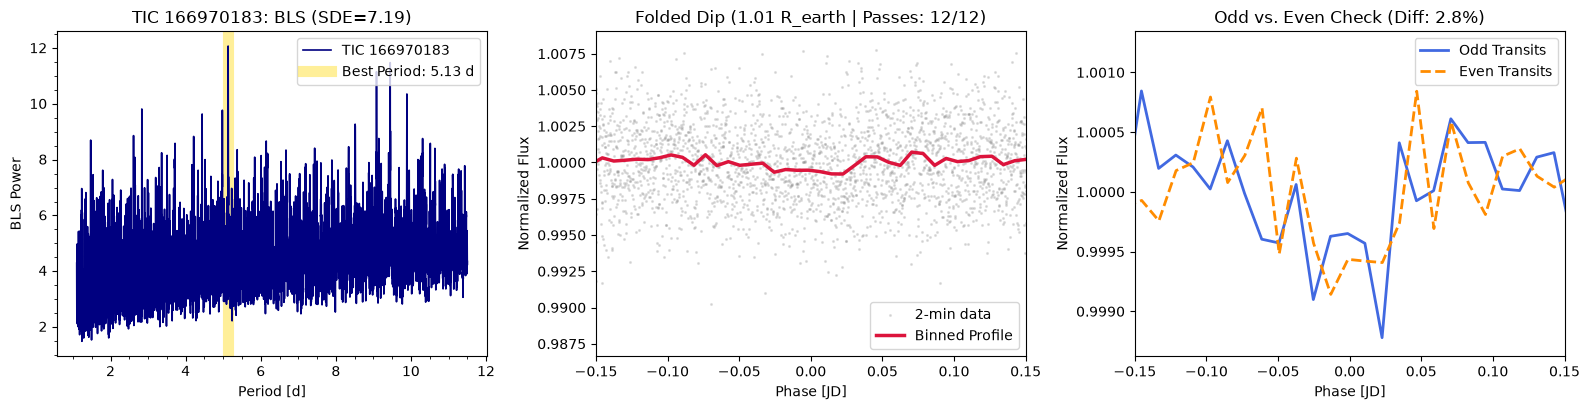


[5/9] === TIC 41460255 | PASS: Coherent Candidate ===
SDE: 6.96 | Period: 10.1406 d | Passes Dipped: 3/3 | Dip SNR: 13.52 | Radius: 3.0 R_earth | TSM: 30.8


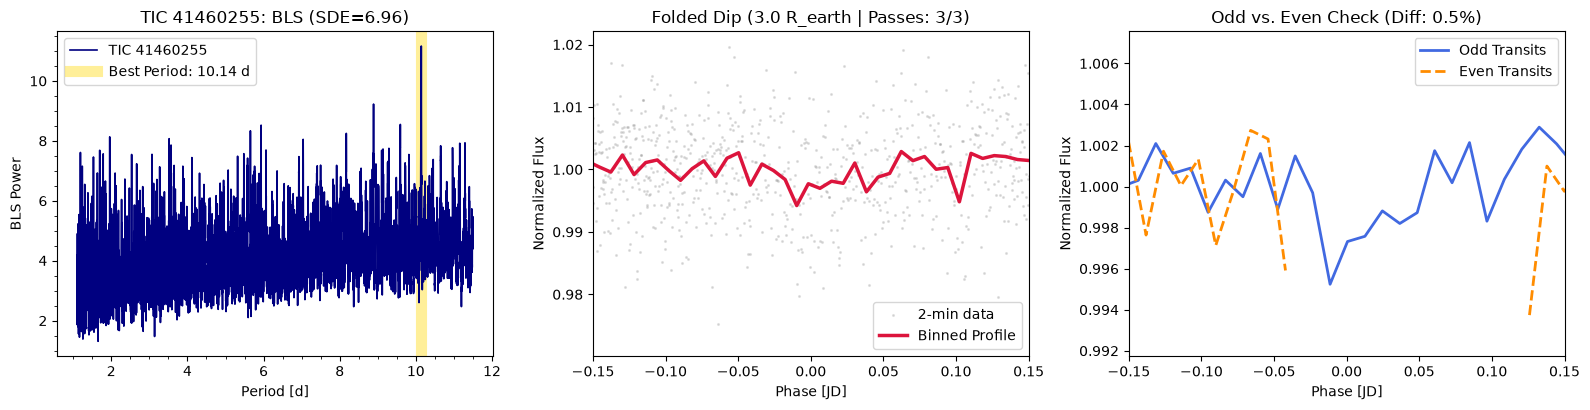


[6/9] === TIC 167305895 | PASS: Coherent Candidate ===
SDE: 6.9 | Period: 11.2774 d | Passes Dipped: 5/5 | Dip SNR: 9.46 | Radius: 1.81 R_earth | TSM: 27.9


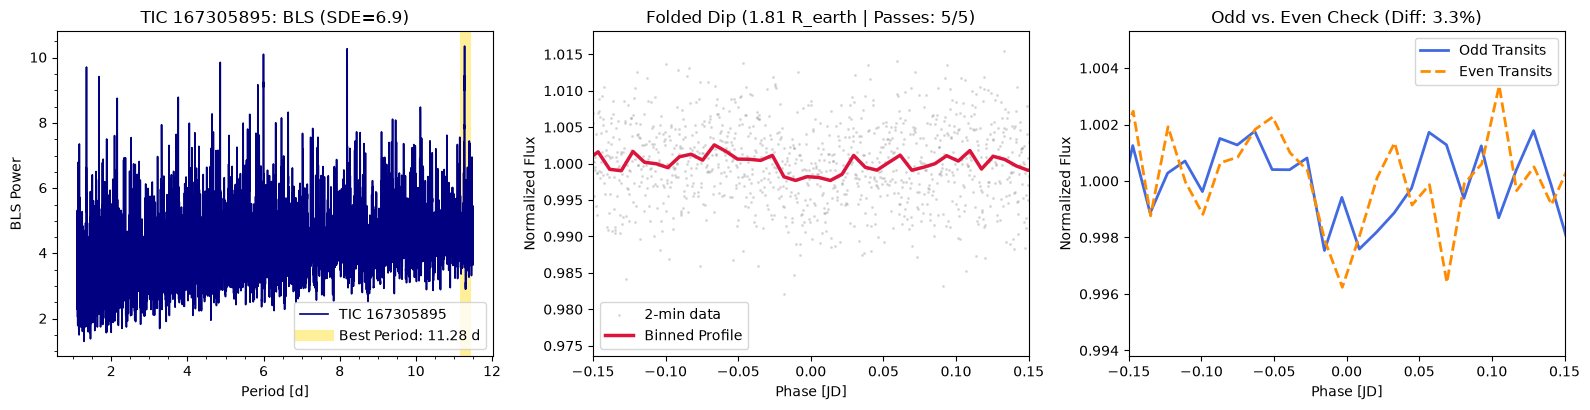


[7/9] === TIC 167244982 | Reject: Wavy/Noisy Baseline (SNR=1.6) ===
SDE: 15.08 | Period: 1.1645 d | Passes Dipped: 42/62 | Dip SNR: 1.61 | Radius: 1.29 R_earth | TSM: 3.8


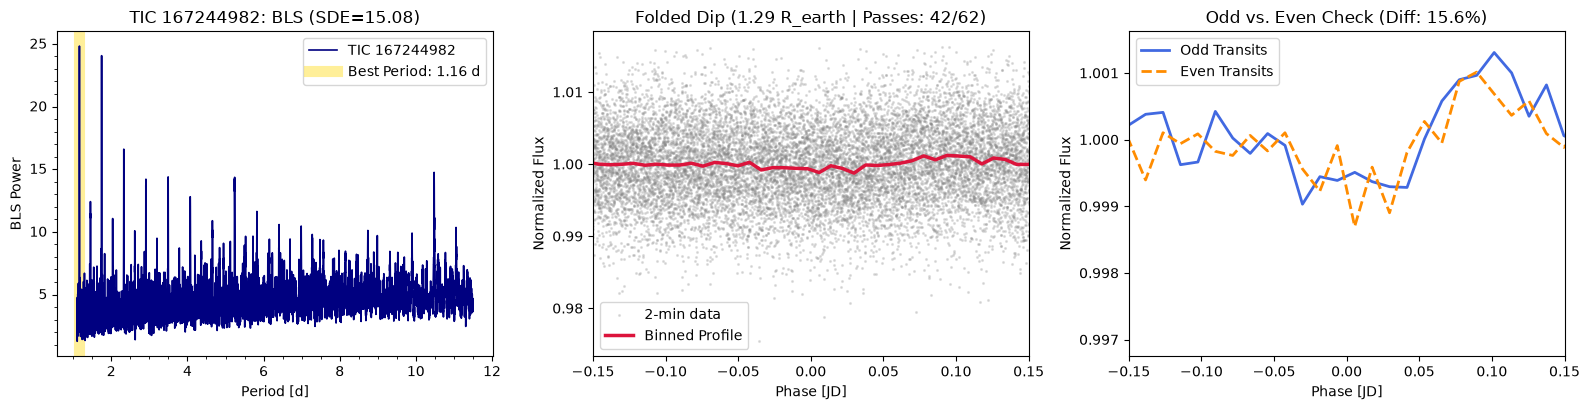


[8/9] === TIC 167305187 | Reject: Inconsistent Passes (8/13) ===
SDE: 8.0 | Period: 7.2169 d | Passes Dipped: 8/13 | Dip SNR: 8.42 | Radius: 1.33 R_earth | TSM: 4.6


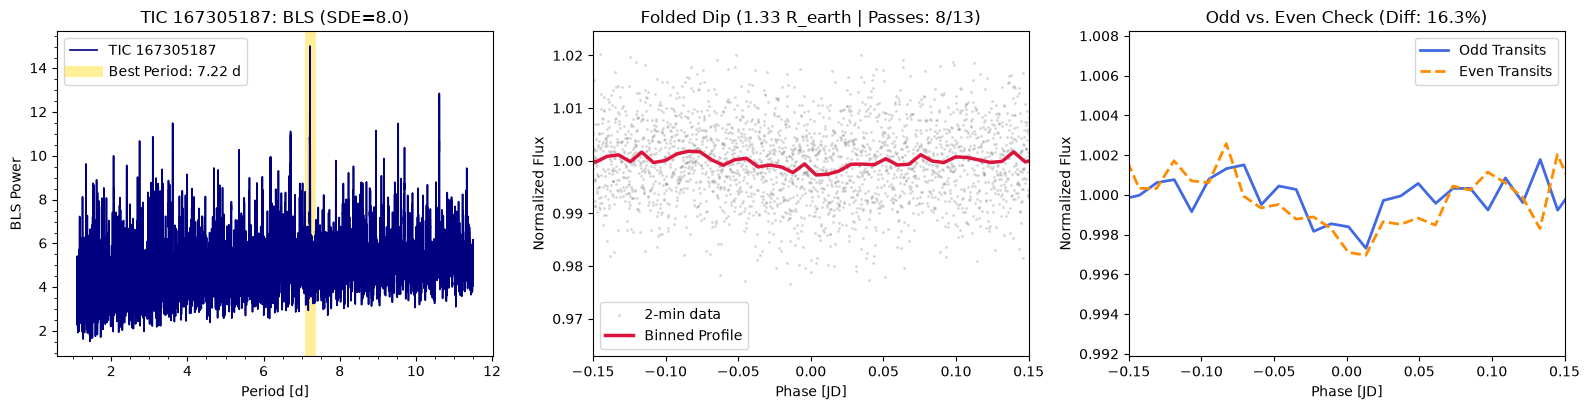


[9/9] === TIC 293347451 | Reject: Inconsistent Passes (12/18) ===
SDE: 6.85 | Period: 3.6753 d | Passes Dipped: 12/18 | Dip SNR: 4.34 | Radius: 1.25 R_earth | TSM: 2.9


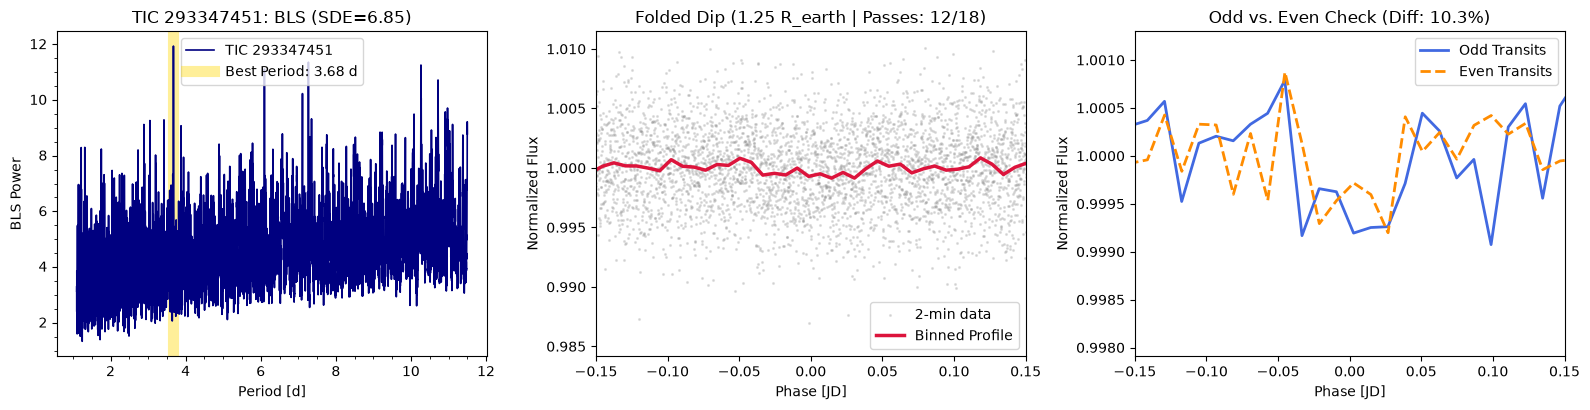

In [23]:
if len(high_sde_candidates) == 0:
    print("No candidates reached the SDE >= 6.4 threshold in this batch.")
else:
    # Sort so "PASS" candidates appear first, then by highest SDE
    sorted_candidates = sorted(
        high_sde_candidates.values(),
        key=lambda x: ("PASS" in x[0]["Vetting Verdict"], x[0]["SDE (Signal Strength)"]),
        reverse=True
    )
    
    for rank, (res, lc, bls) in enumerate(sorted_candidates, 1):
        p = res["Period (d)"]
        t0 = float(bls.transit_time_at_max_power.value)
        
        print(f"\n[{rank}/{len(sorted_candidates)}] === {res['TIC ID']} | {res['Vetting Verdict']} ===")
        print(
            f"SDE: {res['SDE (Signal Strength)']} | Period: {p:.4f} d | "
            f"Passes Dipped: {res['Transits']} | Dip SNR: {res['Dip SNR']} | "
            f"Radius: {res['Est. Radius (R_earth)']} R_earth | TSM: {res['JWST TSM']}"
        )
        
        fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(16, 4.2))
        
        # BLS Periodogram
        bls.plot(ax=ax1, color="navy", lw=1.2, zorder=3)
        ax1.axvline(p, color="gold", lw=8, alpha=0.4, zorder=0, label=f"Best Period: {p:.2f} d")
        ax1.set_title(f"{res['TIC ID']}: BLS (SDE={res['SDE (Signal Strength)']})")
        ax1.legend()
        
        # Phase-Folded Transit Dip
        folded = lc.fold(period=p, epoch_time=t0)
        folded.scatter(ax=ax2, color="gray", alpha=0.2, s=6, label="2-min data")
        folded.bin(time_bin_size=0.008).plot(ax=ax2, color="crimson", lw=2.5, label="Binned Profile")
        ax2.set_xlim(-0.15, 0.15)
        ax2.set_title(f"Folded Dip ({res['Est. Radius (R_earth)']} R_earth | Passes: {res['Transits']})")
        ax2.legend()
        
        # Odd vs. Even Transit Overlay
        folded_odd = lc.fold(period=p * 2, epoch_time=t0)
        folded_even = lc.fold(period=p * 2, epoch_time=t0 + p)
        folded_odd.bin(time_bin_size=0.012).plot(ax=ax3, color="royalblue", lw=2, label="Odd Transits")
        folded_even.bin(time_bin_size=0.012).plot(ax=ax3, color="darkorange", lw=2, linestyle="--", label="Even Transits")
        ax3.set_xlim(-0.15, 0.15)
        ax3.set_title(f"Odd vs. Even Check (Diff: {res['Odd/Even Diff (%)']}%)")
        ax3.legend()
        
        plt.tight_layout()
        plt.show()

## Part 2: Individual Transit Pass Cheat Sheet (Cell 5)

Even if a signal looks clean when folded together in Cell 4, **a real orbiting planet cannot skip orbits**. Because individual passes of small planets have lower Signal-to-Noise (SNR) than the combined stack, individual dips won't look perfectly symmetrical—Instead, check the grid for **consistency across passes**:

1. **The Gold Band Rule (Pass Consistency $\ge 75\%$):**
   * The gold highlight band marks the exact predicted width of the transit (`-0.5 * duration` to `+0.5 * duration`).
   * **✅ Pass:** In at least **3 out of every 4 boxes**, the crimson rolling-average line sags **below** the dashed navy `1.000` baseline inside the gold band.
   * **❌ Reject:** Multiple boxes stay flat at `1.000` or bump **upward** above the baseline inside the gold band (like `TIC 167305895`).

2. **The Center vs. Shoulder Rule (Signal-to-Scatter):**
   * Compare the depth of the red line *inside* the gold band against the white shoulders to the left and right.
   * **✅ Pass:** The dip inside the gold band is the deepest feature in the box, while the left/right shoulders hover near `1.000`.
   * **❌ Reject:** The red line bounces up and down in the white shoulders just as deeply as it does inside the gold band (stellar jitter / starspot ripples).

3. **The "Single Monster Glitch" Rule:**
   * **✅ Pass:** Every dipping pass reaches roughly the **same ballpark depth** (e.g., all dropping to around `0.996–0.998`).
   * **❌ Reject:** One single box plunges way down (e.g., `0.980`) while the other boxes barely move—meaning a single camera glitch or cosmic ray dragged the entire multi-sector average down.

4. **The Data Gap Rule:**
   * **✅ Pass:** Gray 2-minute data dots are distributed continuously right through the center of the gold band.
   * **❌ Reject:** The gold band is mostly empty white space (the predicted transit fell inside a spacecraft data-downlink gap) and the red line is just connecting dots across empty air.


DEEP-DIVE PASS INSPECTION: TIC 150356424 (PASS: Coherent Candidate)
Period: 11.1620 d | Duration: 0.96 hrs | DipPasses: 5/6 | Dip SNR: 10.44 | Radius: 1.83 R_earth


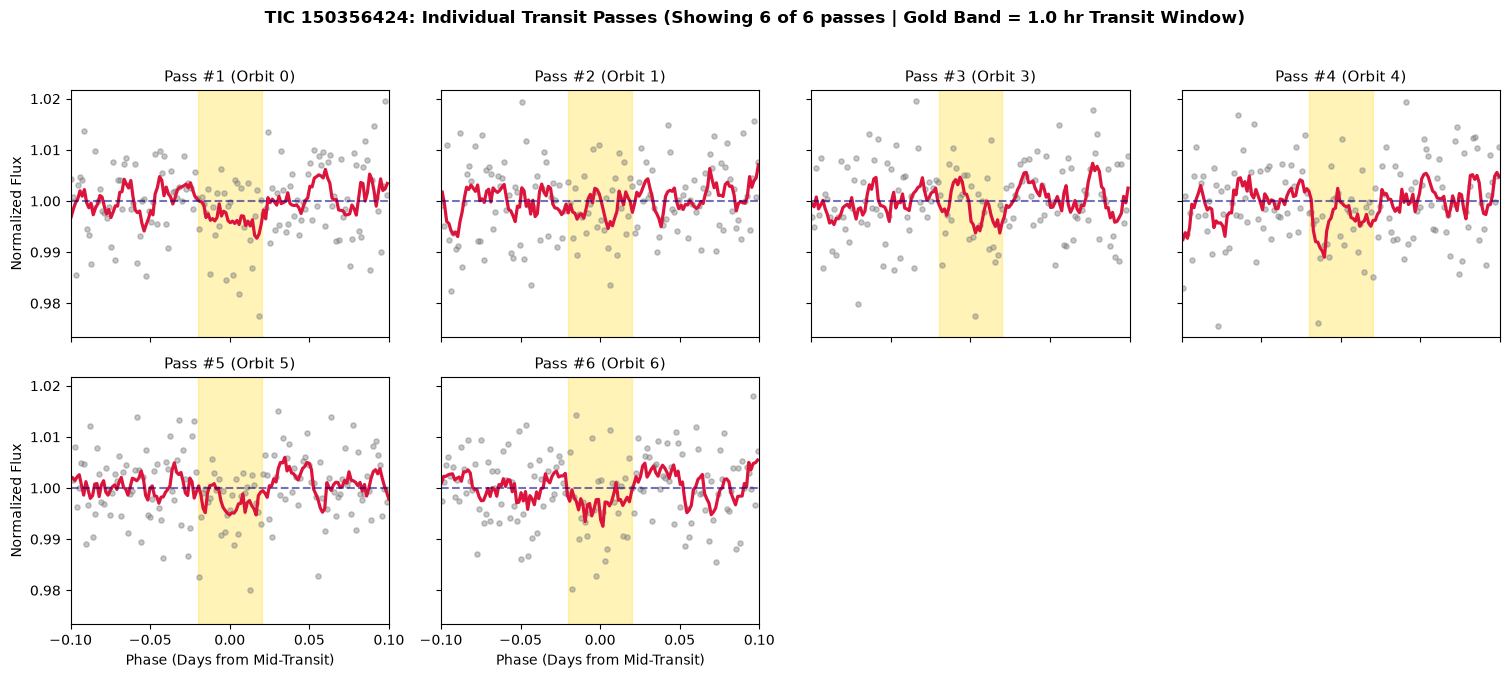


DEEP-DIVE PASS INSPECTION: TIC 375037245 (PASS: Coherent Candidate)
Period: 11.2337 d | Duration: 0.96 hrs | DipPasses: 6/6 | Dip SNR: 14.67 | Radius: 1.65 R_earth


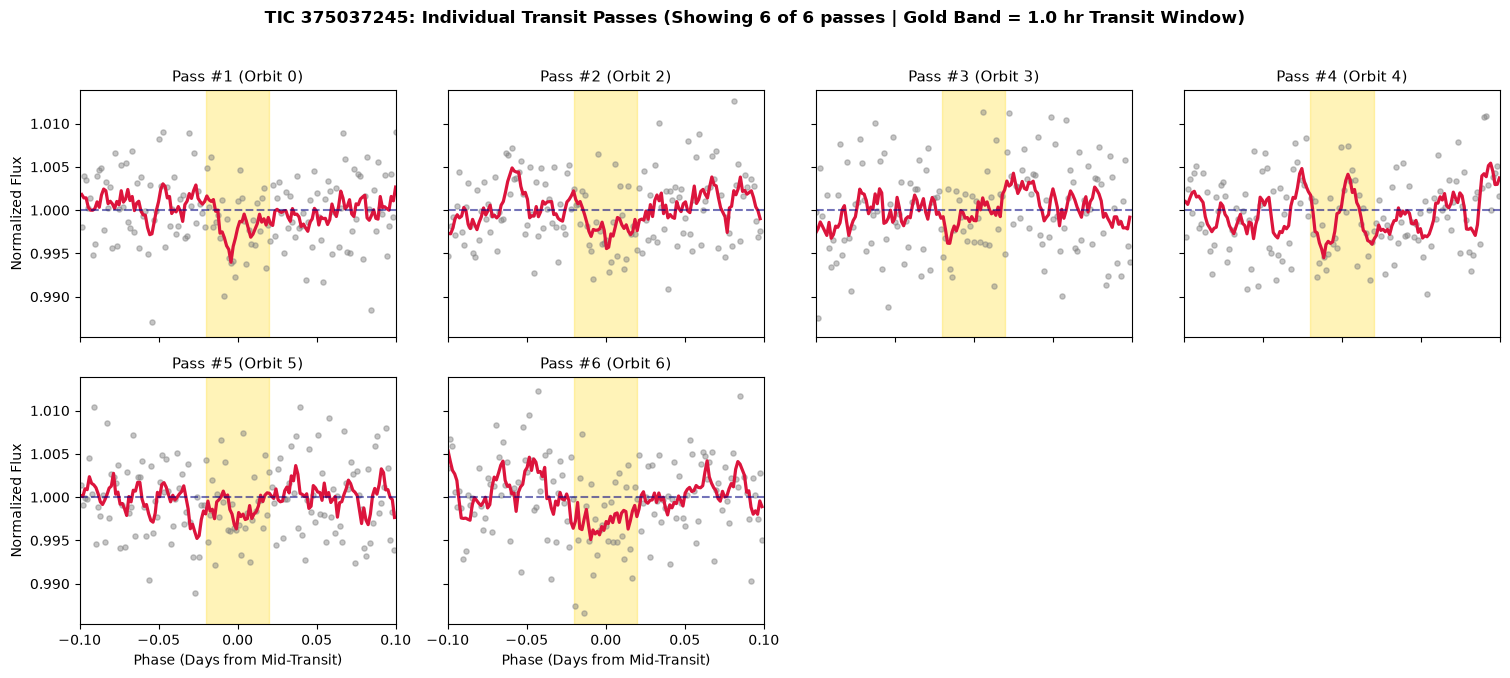


DEEP-DIVE PASS INSPECTION: TIC 150438041 (PASS: Coherent Candidate)
Period: 2.4251 d | Duration: 1.54 hrs | DipPasses: 22/28 | Dip SNR: 2.97 | Radius: 1.12 R_earth


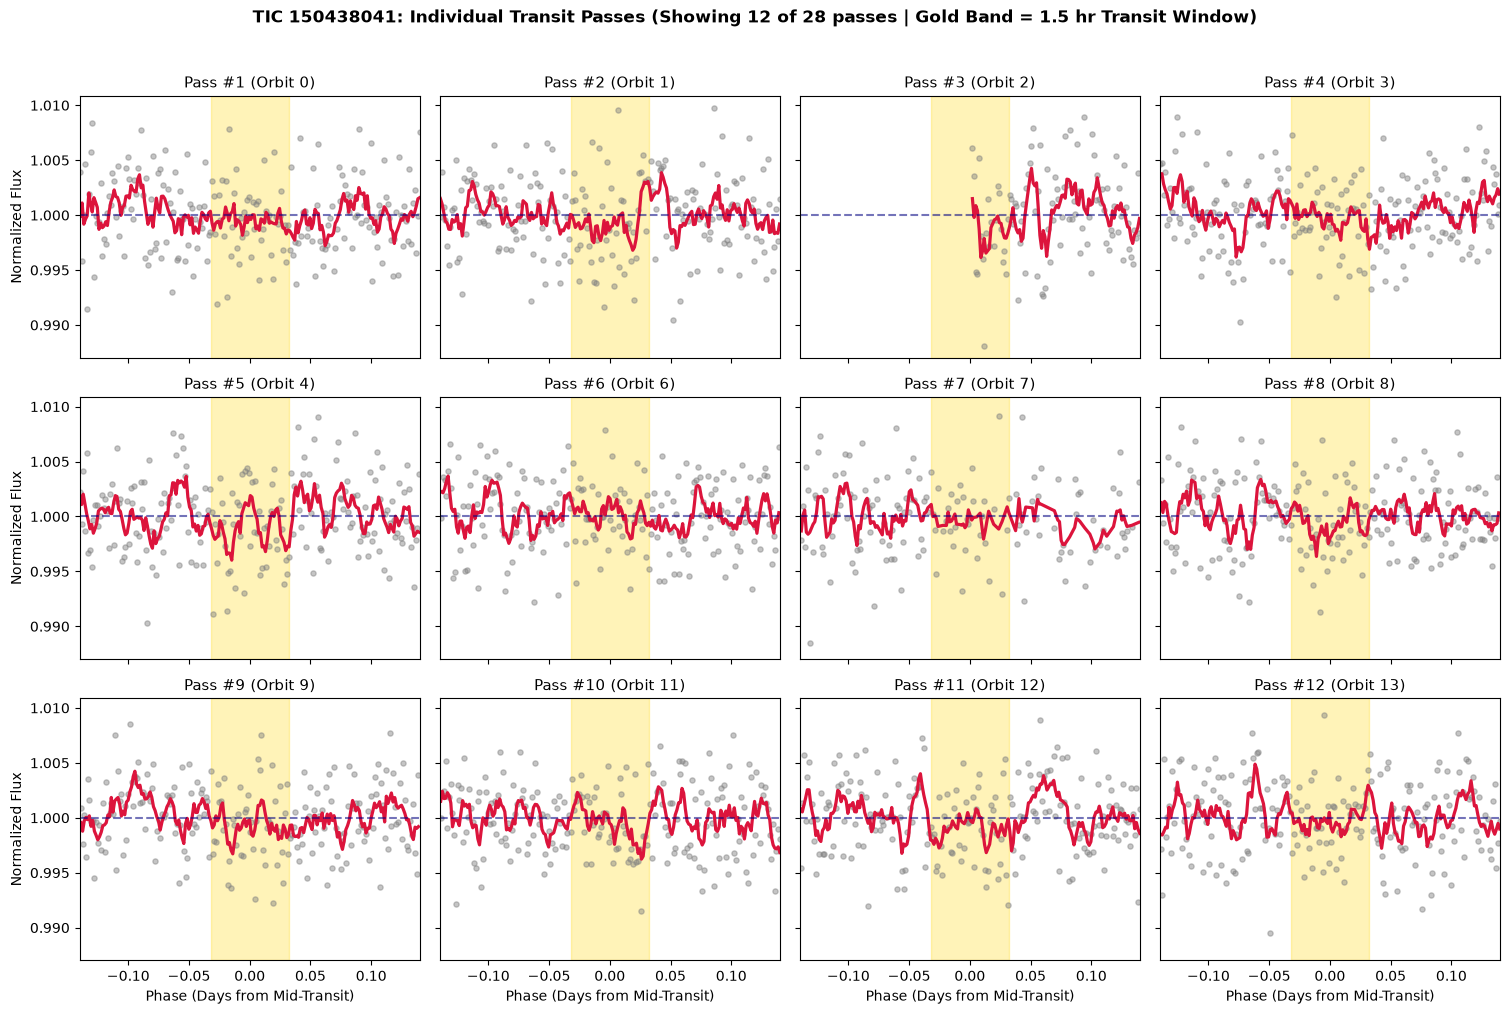


DEEP-DIVE PASS INSPECTION: TIC 166970183 (PASS: Coherent Candidate)
Period: 5.1314 d | Duration: 1.54 hrs | DipPasses: 12/12 | Dip SNR: 6.0 | Radius: 1.01 R_earth


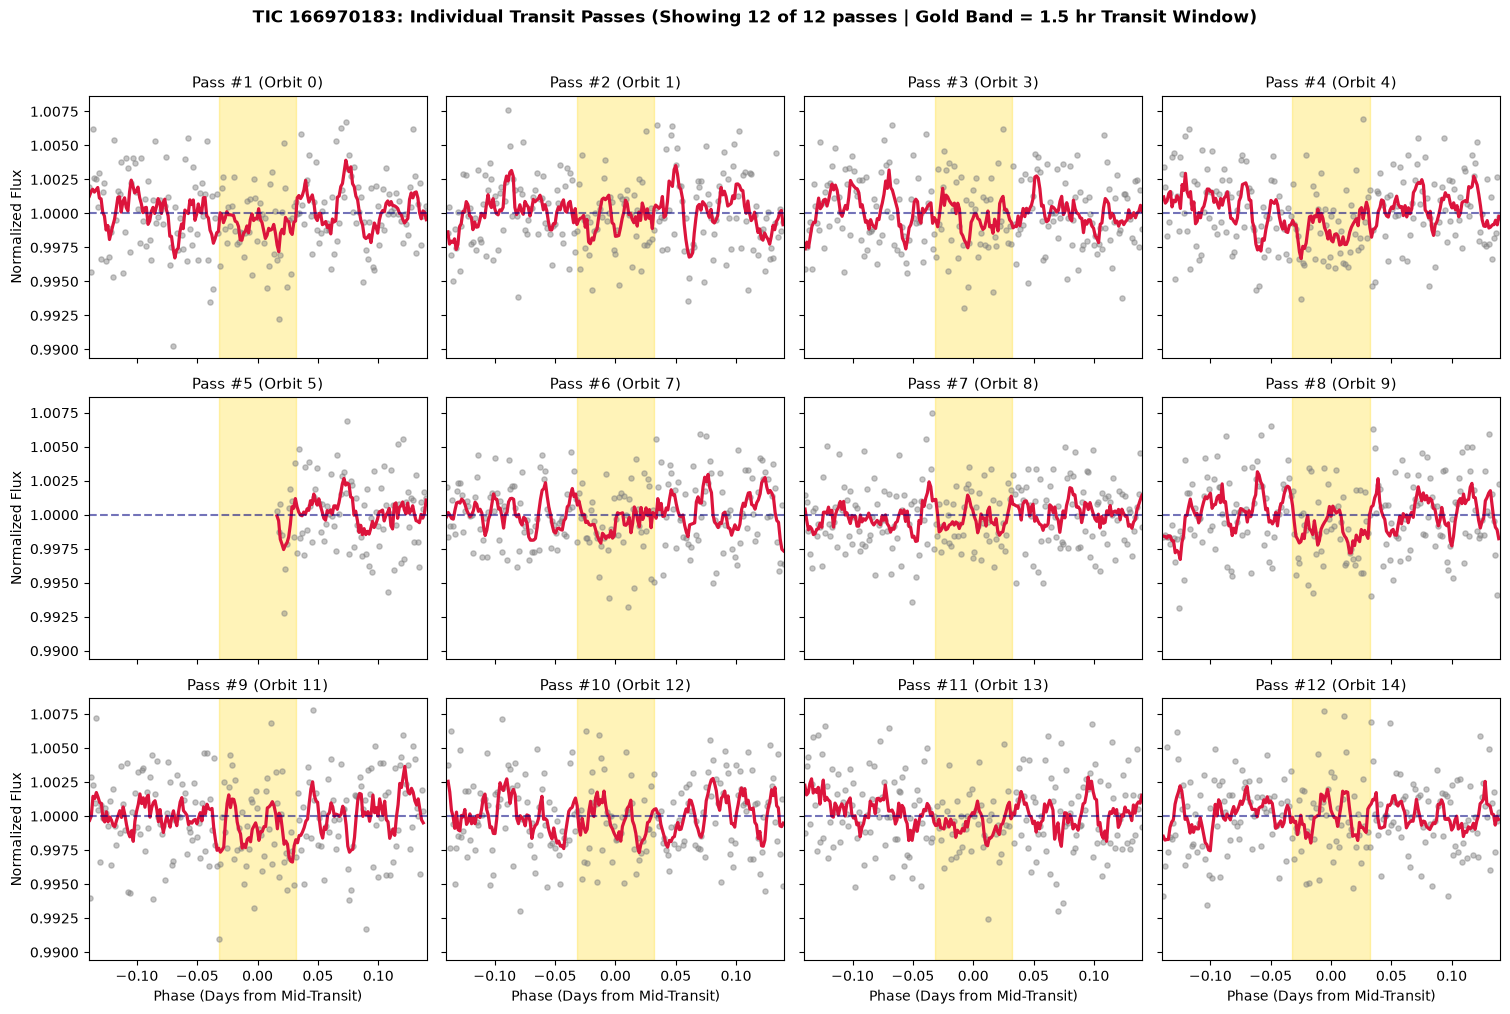


DEEP-DIVE PASS INSPECTION: TIC 41460255 (PASS: Coherent Candidate)
Period: 10.1406 d | Duration: 0.96 hrs | DipPasses: 3/3 | Dip SNR: 13.52 | Radius: 3.0 R_earth


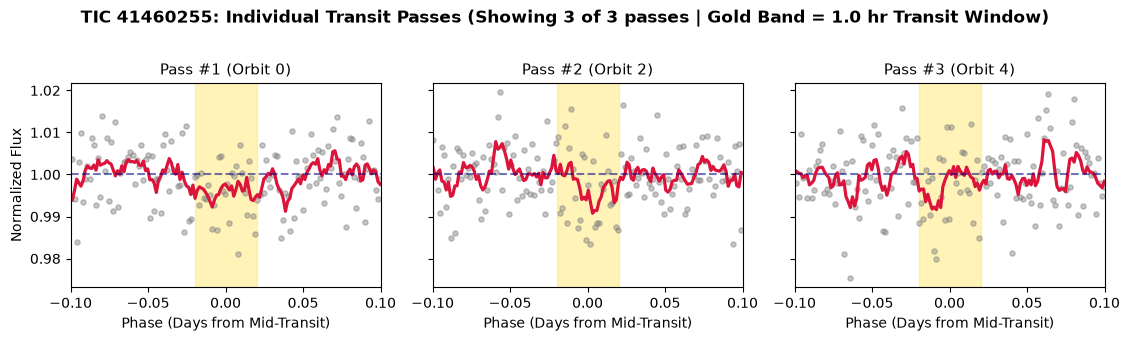


DEEP-DIVE PASS INSPECTION: TIC 167305895 (PASS: Coherent Candidate)
Period: 11.2774 d | Duration: 0.96 hrs | DipPasses: 5/5 | Dip SNR: 9.46 | Radius: 1.81 R_earth


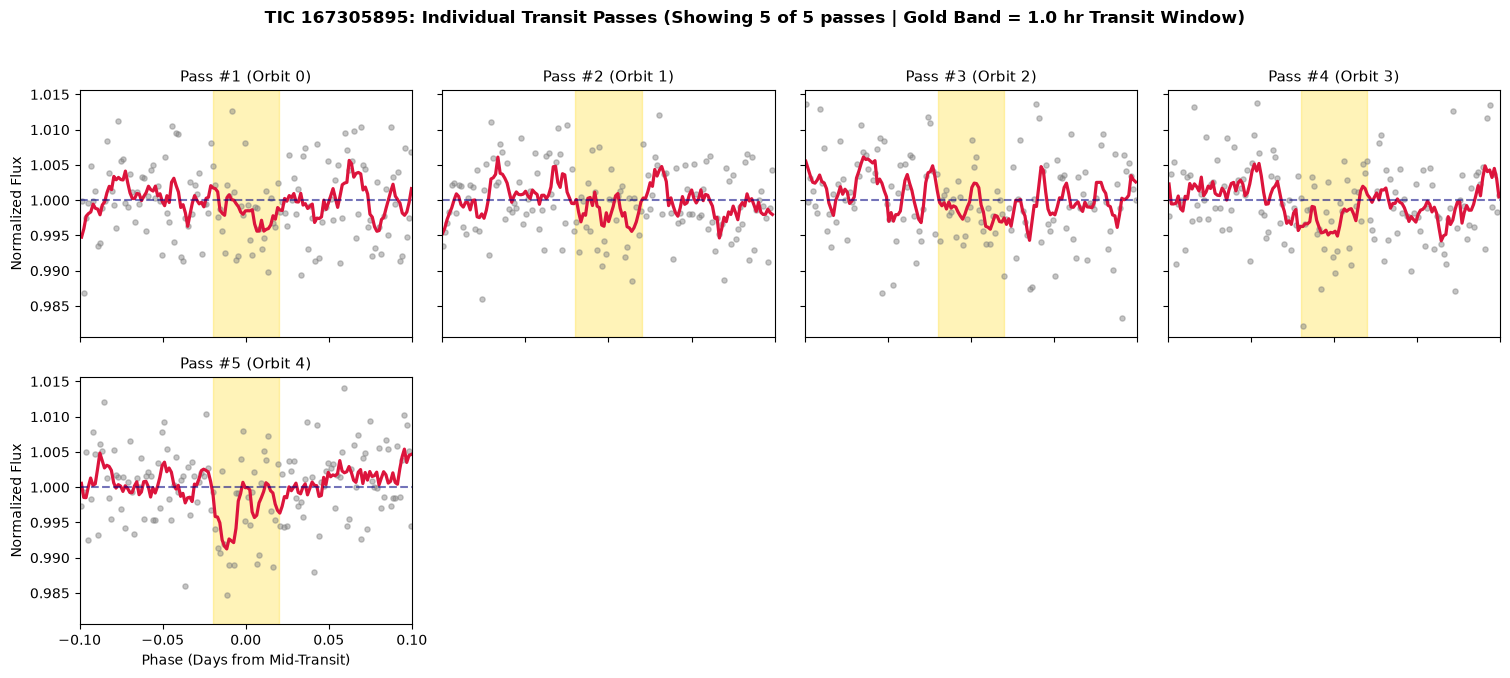

In [25]:
import json
import math

# =====================================================================
# STREAMLINED CANDIDATE INSPECTOR SETTINGS
# - Set INSPECT_MODE = "ALL_PASSING" to auto-plot every star that passed Cell 2's filters.
# - Or set INSPECT_MODE = "BY_RANK" and change RANK_TO_INSPECT (1, 2, 3...) to inspect any row from Cell 4!
# - Set SAVE_TO_DISK = True ONLY when you find a verified keeper you want to save to your folder.
# =====================================================================
INSPECT_MODE = "ALL_PASSING"   # Options: "ALL_PASSING" or "BY_RANK"
RANK_TO_INSPECT = 1            # Used if INSPECT_MODE == "BY_RANK" (or if 0 candidates passed)
MAX_PASSES_TO_SHOW = 12        # Wraps cleanly into rows of 4!
SAVE_TO_DISK = False           # Keep False until you find a real candidate worth saving!

sorted_candidates = sorted(
    high_sde_candidates.values(),
    key=lambda x: ("PASS" in x[0]["Vetting Verdict"], x[0]["SDE (Signal Strength)"]),
    reverse=True
)

if INSPECT_MODE == "ALL_PASSING":
    targets_to_plot = [c for c in sorted_candidates if "PASS" in c[0]["Vetting Verdict"]]
    if len(targets_to_plot) == 0 and len(sorted_candidates) > 0:
        print(f"No candidates passed all automated filters in this batch! Showing Rank #{RANK_TO_INSPECT} instead so you can see why it was rejected:")
        targets_to_plot = [sorted_candidates[min(RANK_TO_INSPECT - 1, len(sorted_candidates) - 1)]]
else:
    targets_to_plot = [sorted_candidates[min(RANK_TO_INSPECT - 1, len(sorted_candidates) - 1)]]

for cand_res, cand_lc, cand_bls in targets_to_plot:
    tic_id = cand_res["TIC ID"]
    safe_name = tic_id.replace(" ", "_")
    p = cand_res["Period (d)"]
    t0 = float(cand_bls.transit_time_at_max_power.value)
    dur = float(cand_bls.duration_at_max_power.value)
    
    # Dynamic X-axis zoom: +/- 2.5x the transit duration (clamped between 0.08 and 0.14 days)
    x_zoom = max(min(dur * 2.5, 0.14), 0.08)
    
    print(f"\n=======================================================")
    print(f"DEEP-DIVE PASS INSPECTION: {tic_id} ({cand_res['Vetting Verdict']})")
    print(f"Period: {p:.4f} d | Duration: {dur*24:.2f} hrs | DipPasses: {cand_res['Transits']} | Dip SNR: {cand_res['Dip SNR']} | Radius: {cand_res['Est. Radius (R_earth)']} R_earth")
    print(f"=======================================================")
    
    t_arr = np.asarray(cand_lc.time.value, dtype=float)
    f_arr = np.asarray(cand_lc.flux.value, dtype=float)
    phase_days = (t_arr - t0 + 0.5 * p) % p - 0.5 * p
    in_window = np.abs(phase_days) <= x_zoom
    orbit_nums = np.round((t_arr - t0) / p).astype(int)
    
    # Only plot individual orbits that have at least 3 data points inside the transit duration
    all_orbits = np.unique(orbit_nums[np.abs(phase_days) <= (0.5 * dur)])
    valid_orbits = [orb for orb in all_orbits if np.sum((orbit_nums == orb) & (np.abs(phase_days) <= 0.5 * dur)) >= 3]
    
    orbits_to_show = valid_orbits[:MAX_PASSES_TO_SHOW]
    n_transits = len(orbits_to_show)
    
    if n_transits > 0:
        # Wrap into a clean grid with a maximum of 4 columns per row!
        n_cols = min(4, n_transits)
        n_rows = math.ceil(n_transits / 4)
        
        fig, axes = plt.subplots(
            n_rows, n_cols,
            figsize=(3.8 * n_cols, 3.3 * n_rows),
            sharex=True, sharey=True,
            squeeze=False
        )
        axes_flat = axes.flatten()
        
        for idx, orb in enumerate(orbits_to_show):
            ax = axes_flat[idx]
            mask = (orbit_nums == orb) & in_window
            sort_idx = np.argsort(phase_days[mask])
            t_slice = phase_days[mask][sort_idx]
            f_slice = f_arr[mask][sort_idx]
            
            # Plot 2-min dots + red rolling average line
            ax.scatter(t_slice, f_slice, color="gray", alpha=0.45, s=14)
            if len(f_slice) >= 5:
                smooth = pd.Series(f_slice).rolling(6, center=True, min_periods=3).mean()
                ax.plot(t_slice, smooth, color="crimson", lw=2.3)
                
            # Dashed 1.000 baseline + Gold band spanning the exact full transit duration (-dur/2 to +dur/2)
            ax.axhline(1.0, color="navy", linestyle="--", alpha=0.55)
            ax.axvspan(-0.5 * dur, 0.5 * dur, color="gold", alpha=0.28, zorder=0, label="Transit Window")
            ax.set_xlim(-x_zoom, x_zoom)
            ax.set_title(f"Pass #{idx+1} (Orbit {orb})", fontsize=10.5)
            
            if idx >= (n_rows - 1) * n_cols:
                ax.set_xlabel("Phase (Days from Mid-Transit)")
            if idx % n_cols == 0:
                ax.set_ylabel("Normalized Flux")
                
        # Hide any unused empty subplot boxes in the bottom row
        for unused_idx in range(n_transits, len(axes_flat)):
            axes_flat[unused_idx].set_visible(False)
            
        plt.suptitle(
            f"{tic_id}: Individual Transit Passes (Showing {n_transits} of {len(valid_orbits)} passes | Gold Band = {dur*24:.1f} hr Transit Window)",
            y=1.02, fontsize=12.5, fontweight="bold"
        )
        plt.tight_layout()
        
        if SAVE_TO_DISK:
            cand_lc.to_pandas().to_csv(f"candidate_{safe_name}_lightcurve.csv", index=False)
            with open(f"candidate_{safe_name}_summary.json", "w") as f:
                json.dump(cand_res, f, indent=4)
            plt.savefig(f"candidate_{safe_name}_vetting.png", dpi=150, bbox_inches="tight")
            print(f"  -> Saved {tic_id} CSV, JSON, and PNG to disk!")
            
        plt.show()